# STA2112 Homework 1 (v2)

**Name:** Alec Neme  
**Student number:** 1084575857

## Q1: Prediction targets and evaluation

### Q1(a)

**(i)** The first priority should be removing patient ID. Patient ID does not help us predict for new patients, since a new patient's ID was not seen in the training data. Moreover, the hospital does not assign IDs based on how likely patients are to be readmitted; they are probably sequential numbers assigned as new patients arrive. Furthermore, if a patient is frequently readmitted, patients with similar IDs may be given a higher predicted likelihood of readmission, even though this is not a real feature of the data, simply because that patient reappears in the training data. Thus, keeping patient IDs lead to information leakage, since it reveals the data source. I would also remove the current length of hospital stay, since for a new patient this information is available only after the prediction is made.

**(ii)** A totally random assignment can be misleading here because we could be splitting a patient's admissions into two. Say patient 4 was admitted a total of 4 times. If we get a split where 2 admissions are in the training and 2 are in the testing split, then the model will have already seen the patient's information, leading to lower errors than they should be. Additionally, we are not guaranteed to have the admissions ordered; we could have later admissions in the testing split, with admissions that already happened in the training split. This is why it is important to keep patients whole (i.e., a patient's admssions are only in the training or the testing split). 

### Q1(b)

**(i)** This is a problem because we are standardizing on all the data; this means that we are taking into account the variation of both the training and testing sets, which will lead to artificially lower errors. What we want to do here is only standardize with the training data, within each CV fold. Similarly, using predictors with higher correlation to the outcome variable after training with the whole dataset is double-dipping. The data we are using is no longer independent of the model we are trying to fit, which will lead to artificial results. Predictor selection should be done before we actually train the model, using EDA.

**(ii)** Here, the $k$ chosen is valid; we generally want to choose the value that gets us the lowest CV validation error (or within one standard error). The mistake here is how we are reporting the model benchmark: using the lowest CV error is wrong, since we are optimizing the model with information that is already known to it. To fix this, we need to use the model with the chosen $k$, refit it on all of the training set (without the CV folds), and then use the testing set to report the error as the final evaluation.

### Q1(c)

**(i)** Write $p = p(x)$ and $\hat p = \hat p_D(x)$.

$$
\begin{aligned}
\mathbb{E}_{D,Y}\big[(Y-\hat p_D(x))^2\big] &= \mathbb{E}_{D,Y}\big[\big((Y-p)+(p-\hat p)\big)^2\big]\\
&= \mathbb{E}_{D,Y}\big[(Y-p)^2 + 2(Y-p)(p-\hat p) + (p-\hat p)^2\big]\\
&= \mathbb{E}_{D,Y}\big[(Y-p)^2\big] - 2\,\mathbb{E}_{D,Y}\big[(Y-p)(p-\hat p)\big] + \mathbb{E}_{D,Y}\big[(p-\hat p)^2\big]
\end{aligned}
$$

First term: $\mathbb{E}_{D,Y}[(Y-p)^2] = \operatorname{Var}(Y) = p(x)(1-p(x))$.

Cross term: since $Y \perp \hat p_D(x)$, $2\,\mathbb{E}[(Y-p)(p-\hat p)] = 2\,\mathbb{E}[Y-p]\,\mathbb{E}[p-\hat p]$, and $\mathbb{E}[Y]-p = p-p = 0$, so the cross term vanishes.

With $\mu(x) = \mathbb{E}_D[\hat p_D(x)]$:

$$
\begin{aligned}
\therefore\ \mathbb{E}_{D,Y}\big[(Y-\hat p_D(x))\big] &= \mathbb{E}_{D,Y}\big[(p(x)-\hat p_D(x))^2\big] + p(x)(1-p(x))\\
&= \mathbb{E}_{D,Y}\big[\big((p(x)+\mu(x)) + (\mu(x)-\hat p_D(x))\big)^2\big] + p(x)(1-p(x))
\end{aligned}
$$

where

$$
\begin{aligned}
\mathbb{E}_{D,Y}\big[\big((p(x)+\mu(x)) + (\mu(x)-\hat p_D(x))\big)^2\big]
&= \mathbb{E}\,(p(x)-\mu(x))^2 + 2\,\mathbb{E}_{D,Y}\big[(p(x)-\mu(x))(\mu(x)-\hat p_D(x))\big] + \mathbb{E}_{D,Y}\big[(\mu(x)-\hat p_D(x))^2\big]\\
&= \mathbb{E}\,(p(x)-\mu(x))^2 + 2\,(p(x)-\mu(x))\big(\mu(x)-\mathbb{E}[\hat p_D(x)]\big) + \mathbb{E}_{D,Y}\big[(\mu(x)-\hat p_D(x))^2\big]
\end{aligned}
$$

Since $\mathbb{E}[\hat p_D(x)] = \mu(x)$, the middle term is $0$, and $\mathbb{E}_{D,Y}[(\mu(x)-\hat p_D(x))^2] = \operatorname{Var}_D(\hat p_D(x))$, and ${E}\,(p(x)-\mu(x))^2 = (\mu(x) - p(x))^2$, since they're constant. Therefore

$$
\begin{aligned}
\mathbb{E}_{D,Y} &= \mathbb{E}\big[(p(x)-\mu(x))^2\big] + \mathbb{E}_{D,Y}\big[(\mu(x)-\hat p_D(x))^2\big] + p(x)(1-p(x))\\
&= (\mu(x)-p(x))^2 + \operatorname{Var}_D(\hat p_D(x)) + p(x)(1-p(x)).
\end{aligned}
$$

**(ii)** No. We always have the variance of $Y$, $p(x)(1-p(x))$, which is why, even if we fit perfectly, the variance from the random variable (our irreducible error) does not translate to perfect predictions.

## Q2: Regularization and shrinkage

### Q2(a)

**(i)** Let $L(\beta) = \|y - X\beta\|_2^2$ and
$P(\beta) = \|\beta\|_2^2 = \sum_j \beta_j^2$, or $\|\beta\|_1 = \sum_j |\beta_j|$, subject to $\|\beta\|_2^2 \le t$ or $\|\beta\|_1 \le t$, where $t = P(\hat\beta(\lambda))$,
and $P(\hat\beta) \le P(\hat\beta(\lambda)) \Rightarrow$ feasible.

$$L(\hat\beta) + \lambda P(\hat\beta) \le L(\beta) + \lambda P(\beta) \quad \forall \beta \in \mathbb{R}^p$$

For both ridge and lasso, $\|\beta\|_2^2 \le t$, $\|\beta\|_1 \le t$.

Since we are dealing with a minimizer,

$$
\begin{aligned}
L(\hat\beta) + \lambda P(\hat\beta) &\le L(\beta) + \lambda P(\beta)\\
L(\hat\beta) &\le L(\beta) + \lambda\big(P(\beta) - P(\hat\beta)\big) \qquad (\hat\beta \text{ is feasible})
\end{aligned}
$$

Assuming a feasible $\beta$, $P(\beta) \le P(\hat\beta)$, and $\lambda > 0$,

$$
\begin{aligned}
\therefore\ \lambda\big(P(\beta) - P(\hat\beta)\big) &\le 0\\
\Rightarrow\ L(\hat\beta) \le L(\beta) + \lambda\big(P(\beta) - P(\hat\beta)\big) &\le L(\beta) + 0\\
\Rightarrow\ L(\hat\beta) &\le L(\beta)
\end{aligned}
$$

Thus $\hat\beta$ is feasible, and $L(\hat\beta) \le L(\beta)$ for every feasible $\beta$, so $\hat\beta$ minimizes $L$ subject to $P(\beta) \le P(\hat\beta(\lambda))$.

**(ii)** We need to show that, for all $\beta \in \mathbb{R}^p$,

$$L(\tilde\beta) + \lambda P(\tilde\beta) \le L(\beta) + \lambda P(\beta).$$

*Proof.* $\tilde\beta$ is a constrained minimizer, which minimizes $L$ among feasible points, and $\hat\beta$ is feasible. Therefore,

$$L(\tilde\beta) \le L(\hat\beta).$$

Since $\tilde\beta$ minimizes $L$, $P(\tilde\beta) \le P(\hat\beta)$, and since $\lambda > 0$, multiplying by $\lambda$ keeps the inequality the same (it does not reverse it), so

$$\lambda P(\tilde\beta) \le \lambda P(\hat\beta).$$

Thus,

$$L(\tilde\beta) + \lambda P(\tilde\beta) \le L(\hat\beta) + \lambda P(\hat\beta).$$

From part (i), we showed that, for all $\beta \in \mathbb{R}^p$,

$$L(\hat\beta) + \lambda P(\hat\beta) \le L(\beta) + \lambda P(\beta).$$

Therefore, for all $\beta \in \mathbb{R}^p$,

$$L(\tilde\beta) + \lambda P(\tilde\beta) \le L(\hat\beta) + \lambda P(\hat\beta) \le L(\beta) + \lambda P(\beta). \qquad \blacksquare$$

### Q2(b)

Let $\hat\beta_1 = \hat\beta(\lambda_1)$, $\hat\beta_2 = \hat\beta(\lambda_2)$, $L_1 = L(\hat\beta_1)$, $L_2 = L(\hat\beta_2)$, $P_1 = P(\hat\beta_1)$, and $P_2 = P(\hat\beta_2)$.

Then, since each $\hat\beta_k$ is a minimizer, the following inequalities hold for every $\beta \in \mathbb{R}^p$:

$$
\begin{aligned}
L_1 + \lambda_1 P_1 &\le L(\beta) + \lambda_1 P(\beta). \quad \text{Choose } \beta = \hat\beta_2 \;\Rightarrow\; L_1 + \lambda_1 P_1 \le L_2 + \lambda_1 P_2\\
L_2 + \lambda_2 P_2 &\le L(\beta) + \lambda_2 P(\beta). \quad \text{Choose } \beta = \hat\beta_1 \;\Rightarrow\; L_2 + \lambda_2 P_2 \le L_1 + \lambda_2 P_1
\end{aligned}
$$

Adding the two inequalities and cancelling $L_1$ and $L_2$, which appear on both sides:

$$
\begin{aligned}
L_1 + \lambda_1 P_1 + L_2 + \lambda_2 P_2 &\le L_2 + \lambda_1 P_2 + L_1 + \lambda_2 P_1\\
\lambda_1 P_1 + \lambda_2 P_2 &\le \lambda_1 P_2 + \lambda_2 P_1\\
(\lambda_2 - \lambda_1) P_2 &\le (\lambda_2 - \lambda_1) P_1\\
(\lambda_2 - \lambda_1)\, P(\hat\beta(\lambda_2)) &\le (\lambda_2 - \lambda_1)\, P(\hat\beta(\lambda_1))
\end{aligned}
$$

Simplifying by dividing both sides by $(\lambda_2 - \lambda_1)$: since $\lambda_2 - \lambda_1 > 0$, this keeps the inequality the same (it does not reverse it).

$$\therefore\; P(\hat\beta(\lambda_2)) \le P(\hat\beta(\lambda_1)). \qquad \blacksquare$$

### Q2(c)

Throughout, $X$ is fixed, so $x_i$, $s$, $\lambda$ and $\beta$ are constants; all expectations and variances are conditional on $X$. Substituting $y_i = x_i\beta + \varepsilon_i$ into the numerator and using $\sum_i x_i^2 = s$:

$$\hat{\beta}_{\text{ridge}}(\lambda) = \frac{\sum_i x_i(x_i\beta + \varepsilon_i)}{s + \lambda} = \frac{\beta \sum_i x_i^2 + \sum_i x_i\varepsilon_i}{s + \lambda} = \frac{s\beta}{s + \lambda} + \frac{\sum_i x_i\varepsilon_i}{s + \lambda}.$$

**(i)** By linearity of expectation,

$$\mathbb{E}\big[\hat{\beta}_{\text{ridge}}(\lambda) \mid X\big] = \frac{s\beta}{s + \lambda} + \frac{1}{s + \lambda} \sum_i x_i\, \mathbb{E}[\varepsilon_i \mid X] = \frac{s\beta}{s + \lambda},$$

since $\mathbb{E}[\varepsilon_i \mid X] = 0$ for all $i$. Therefore,

$$\operatorname{Bias}\big(\hat{\beta}_{\text{ridge}}(\lambda) \mid X\big) = \mathbb{E}\big[\hat{\beta}_{\text{ridge}}(\lambda) \mid X\big] - \beta = \frac{s\beta}{s + \lambda} - \beta = \frac{s\beta - (s + \lambda)\beta}{s + \lambda} = -\frac{\lambda\beta}{s + \lambda}.$$

Check: at $\lambda = 0$ the bias is $0$, confirming that the OLS estimator is unbiased.

**(ii)** The first term $\frac{s\beta}{s+\lambda}$ is constant, and $\operatorname{Var}(c + Z) = \operatorname{Var}(Z)$; also $\operatorname{Var}(aZ) = a^2 \operatorname{Var}(Z)$. Since the errors are independent, all covariance terms $\operatorname{Cov}(x_i\varepsilon_i, x_j\varepsilon_j)$ for $i \ne j$ are zero, and each constant $x_i$ comes out of $\operatorname{Var}(x_i\varepsilon_i)$ as $x_i^2$:

$$
\begin{aligned}
\operatorname{Var}\big(\hat{\beta}_{\text{ridge}}(\lambda) \mid X\big)
&= \frac{1}{(s + \lambda)^2} \operatorname{Var}\Big(\sum_i x_i\varepsilon_i \,\Big|\, X\Big)
= \frac{1}{(s + \lambda)^2} \sum_i x_i^2 \operatorname{Var}(\varepsilon_i \mid X)\\
&= \frac{\sigma^2 \sum_i x_i^2}{(s + \lambda)^2}
= \frac{s\sigma^2}{(s + \lambda)^2}.
\end{aligned}
$$

Check: at $\lambda = 0$ this is $\frac{\sigma^2}{s} = \frac{\sigma^2}{\sum_i x_i^2}$, the variance of the single-predictor OLS estimator.

### Q2(d)

**(i)** Ridge and Lasso regression are variance reducing techniques. As we increase $\lambda$, the absolute bias will increase since, after rewriting as $\frac{\lambda}{s+\lambda} = 1 - \frac{s}{s+\lambda}$, it is in the denominator, and making it larger reduces what we subtract from 1, while the variance decreases since it is in the denominator. Conversely, as we decrease $\lambda$, the absolute bias decreases (reaching $0$ at $\lambda = 0$, the OLS estimator) and the variance increases.

**(ii)** By increasing $\lambda$, our variance decreases and our absolute bias increases. As $\lambda$ goes to infinity, $\hat\beta$ shrinks toward $0$, so the absolute bias goes to $|\beta|$ and the variance to $0$; since $\text{MSE} = \text{Bias}^2 + \text{Var}$, the MSE approaches $\beta^2$. So no, a smaller variance alone does not guarantee a smaller MSE: the MSE decreases only if the reduction in variance outweighs the increase in squared bias, and $\beta^2$ can be larger than the OLS MSE $\sigma^2/s$.

## Q3: CV and the one-standard-error rule

### Q3(a)

**(i)** The minimum CV MSE is at $k = 9$, with CV MSE $= 0.18$. Using the one-SE rule, the cutoff is $0.18 + 0.03 = 0.21$. Since $k = 25$ has CV MSE $= 0.20 \le 0.21$, we can increase to $k = 25$ for a smoother model, so $k = 25$ is the simplest eligible choice.

**(ii)** The minimum CV MSE is $0.41$, at 9 leaves. Using the one-SE rule, the cutoff is $0.41 + 0.03 = 0.44$. Since a tree with fewer leaves is simpler, and the 3-leaf tree has CV MSE $= 0.43 \le 0.44$, we would switch to the 3-leaf tree instead.

### Q3(b)

**(i)** No. The CV MSEs are only estimates of the prediction error, and the one-SE rule is a heuristic: being within the cutoff tells us that the CV folds cannot separate the difference between the candidates from the noise, but it does not mean that their errors will be equal.

**(ii)** No, because test sets are obtained by sampling, which is random. In expectation the two test MSEs should be the same, but it is highly unlikely that the two samples will contain the same test observations, which will lead to different realized test MSEs.

## Q4: Classification, margins, and decisions

### Q4(a)

### Q4(a)

**(i)** Differentiating each term with respect to $z$: since $y$ does not depend on $z$, $\frac{\partial}{\partial z}(yz) = y$. For the first term, let $u = 1+e^z$, so $u' = e^z$, and by the chain rule $\frac{d}{dz}\log(u) = \frac{u'}{u}$. Therefore,

$$\frac{\partial \ell(y,z)}{\partial z} = \frac{e^z}{1+e^z} - y.$$

Multiplying the numerator and denominator of $p$ by $e^z$,

$$p = \frac{1}{1+e^{-z}} \cdot \frac{e^z}{e^z} = \frac{e^z}{e^z + 1},$$

so

$$\frac{\partial \ell(y,z)}{\partial z} = p - y.$$

**(ii)** Differentiating again, $y$ is constant in $z$, so

$$\frac{\partial^2 \ell(y,z)}{\partial z^2} = \frac{dp}{dz}.$$

Writing $p = (1+e^{-z})^{-1}$ and applying the chain rule,

$$\frac{dp}{dz} = -(1+e^{-z})^{-2}\cdot(-e^{-z}) = \frac{e^{-z}}{(1+e^{-z})^2} = \left(\frac{1}{1+e^{-z}}\right)\left(\frac{e^{-z}}{1+e^{-z}}\right).$$

The first factor is $p$. Adding and subtracting $1$ in the numerator of the second factor,

$$\frac{e^{-z}}{1+e^{-z}} = \frac{1+e^{-z}-1}{1+e^{-z}} = 1 - \frac{1}{1+e^{-z}} = 1 - p.$$

Therefore,

$$\frac{\partial^2 \ell(y,z)}{\partial z^2} = p(1-p).$$

### Q4(b)

Let $\hat{y} \in \{0,1\}$ be the predicted class and $p = p(x) = \mathbb{P}(y=1 \mid x)$, so $\mathbb{P}(y=0 \mid x) = 1-p$. A false negative costs $4$, a false positive costs $1$, and correct decisions cost $0$.

**(i)** The expected costs of the two decisions are

$$
\begin{aligned}
\mathbb{E}[\text{Cost} \mid \hat{y}=1, x] &= C(1,1)\,p + C(1,0)\,(1-p) = 0\cdot p + 1\cdot(1-p) = 1-p,\\
\mathbb{E}[\text{Cost} \mid \hat{y}=0, x] &= C(0,1)\,p + C(0,0)\,(1-p) = 4\cdot p + 0\cdot(1-p) = 4p.
\end{aligned}
$$

We predict $\hat{y}=1$ when its expected cost is no larger:

$$1-p \le 4p \iff 1 \le 5p \iff p \ge \tfrac{1}{5} = 0.20.$$

So the optimal threshold is $p^* = 0.20$: predict $\hat{y}=1$ if $p(x)

### Q4 SVM options

**Chosen options:** _TODO_ and _TODO_ (exactly two of A, B, C, D)

### Q4 Option C: Slack and hinge loss

$$\min_{w,b,\xi}\ \frac12\|w\|^2 + C\sum_i \xi_i \quad \text{subject to} \quad \xi_i \ge 0, \quad y_i(w^\top x_i + b) \ge 1 - \xi_i \quad \forall i.$$

**(i)** Holding $w$ and $b$ fixed, each signed score $m_i = y_i(w^\top x_i + b)$ is a constant. Rearranging the margin constraint gives $\xi_i \ge 1 - y_i(w^\top x_i + b)$; combined with $\xi_i \ge 0$, $\xi_i$ is feasible if and only if

$$\xi_i \ge \max\big(0,\ 1 - y_i(w^\top x_i + b)\big).$$

So the smallest feasible slack is

$$\xi_i^*(w,b) = \max\big(0,\ 1 - y_i(w^\top x_i + b)\big) = \big(1 - y_i(w^\top x_i + b)\big)_+.$$

This minimizes the objective over the slacks: with $w, b$ fixed, $\frac12\|w\|^2$ is constant, each $\xi_i$ appears only in its own constraints, and since $C > 0$ the objective is strictly increasing in each $\xi_i$. So we minimize each $\xi_i$ separately over $\big[\max(0, 1 - y_i(w^\top x_i + b)), \infty\big)$, which is attained at the lower endpoint $\xi_i^*(w,b)$.

**(ii)** Substituting $\xi_i^*(w,b)$ into the objective gives a problem in $(w,b)$ alone:

$$\min_{w,b}\ \frac12\|w\|^2 + C\sum_i \max\big(0,\ 1 - y_i(w^\top x_i + b)\big),$$

where $\max(0, 1 - m_i)$ is the hinge loss. This gives the same optimal $(w,b)$ because joint minimization over $(w,b,\xi)$ equals minimizing first over $\xi$ for each fixed $(w,b)$, then over $(w,b)$:

$$\min_{w,b,\xi\ \text{feasible}} \Big(\frac12\|w\|^2 + C\sum_i \xi_i\Big) = \min_{w,b}\Big[\frac12\|w\|^2 + C \min_{\substack{\xi_i \ge 0 \\ \xi_i \ge 1 - y_i(w^\top x_i + b)}} \sum_i \xi_i\Big].$$

For every $(w,b)$, the inner minimum is attained at $\xi_i^*(w,b)$ from (i). If $(\hat w, \hat b, \hat\xi)$ is optimal for the slack problem, then $\hat\xi_i = \xi_i^*(\hat w, \hat b)$; otherwise reducing $\hat\xi_i$ to $\xi_i^*$ would strictly lower the objective without violating any constraint. Conversely, any $(\hat w, \hat b)$ minimizing the hinge objective, paired with $\hat\xi_i = \xi_i^*(\hat w, \hat b)$, is feasible and attains the same minimal value in the slack problem. So both formulations have the same optimal $(w,b)$.

### Q4 Option D: Support vectors and kernels

The fitted weight vector is $w = \sum_{i=1}^n a_i y_i x_i$ with $0 \le a_i \le C$; observations with $a_i > 0$ are the support vectors.

**(i)** Substituting $w$ into $f(x) = w^\top x + b$, and using that the transpose distributes over the sum and $a_i, y_i$ are scalars,

$$f(x) = \Big(\sum_{i=1}^n a_i y_i x_i\Big)^\top x + b = \Big(\sum_{i=1}^n a_i y_i x_i^\top\Big) x + b = \sum_{i=1}^n a_i y_i\, \big(x_i^\top x\big) + b.$$

Only support vectors ($a_i > 0$) contribute non-zero terms.

**(ii)** Replacing each inner product $x_i^\top x$ with the RBF kernel $K(x_i, x) = \exp\{-\gamma\|x_i - x\|^2\}$, with refitted weights $a_i$ and intercept $b$,

$$f(x) = \sum_{i=1}^n a_i y_i\, K(x_i, x) + b = \sum_{i=1}^n a_i y_i \exp\{-\gamma\|x_i - x\|^2\} + b.$$

A larger $\gamma$ makes each kernel contribution decay toward zero more quickly as $\|x_i - x\|$ increases, so each support vector influences predictions only in a smaller neighborhood around itself.

## Q5: Trees, averaging, and regularized corrections

### Q5(a)

Let the leaf have $n$ observations with $y_i \in \{0,1\}$ and $\hat p = \frac1n\sum_i y_i$, so every observation is predicted $\hat p$. There are $n\hat p$ positives, each with squared error $(1-\hat p)^2$, and $n(1-\hat p)$ negatives, each with squared error $(0-\hat p)^2 = \hat p^2$. Splitting the sum by class,

$$
\begin{aligned}
\frac1n\sum_{i=1}^n (y_i - \hat p)^2
&= \frac1n\Big[n\hat p(1-\hat p)^2 + n(1-\hat p)\hat p^2\Big]\\
&= \hat p(1-\hat p)\big[(1-\hat p) + \hat p\big] = \hat p(1-\hat p).
\end{aligned}
$$

### Q5(b)

Each tree prediction has $\operatorname{Var}(\hat f_b) = \sigma^2$, and each distinct pair has $\operatorname{Cov}(\hat f_b, \hat f_{b'}) = \rho\sigma\cdot\sigma = \rho\sigma^2$.

**(i)** Since $\operatorname{Var}(cZ) = c^2\operatorname{Var}(Z)$, and the variance of the sum has $B$ variance terms and $B(B-1)$ covariance terms,

$$
\begin{aligned}
\operatorname{Var}\Big(\frac1B\sum_{b=1}^B \hat f_b\Big)
&= \frac{1}{B^2}\Big[\sum_{b=1}^B \operatorname{Var}(\hat f_b) + \sum_{b \ne b'} \operatorname{Cov}(\hat f_b, \hat f_{b'})\Big]
= \frac{B\sigma^2 + B(B-1)\rho\sigma^2}{B^2}\\
&= \frac{\sigma^2}{B} + \Big(1 - \frac1B\Big)\rho\sigma^2
= \sigma^2\Big(\rho + \frac{1-\rho}{B}\Big).
\end{aligned}
$$

**(ii)** As $B \to \infty$, the term $\sigma^2\frac{1-\rho}{B} \to 0$, so

$$\lim_{B\to\infty} \sigma^2\Big(\rho + \frac{1-\rho}{B}\Big) = \rho\sigma^2.$$

The part due to correlation between trees, $\rho\sigma^2$, remains no matter how many trees are averaged.

### Q5(c)

**(i)** Differentiating $L_j(w) = \frac12\sum_{i\in I_j}(r_i - w)^2 + \frac{\lambda}{2}w^2$ (the inner derivative of $(r_i - w)$ is $-1$) and setting it to zero, with $\sum_{i\in I_j} r_i = n_j\bar r_j$:

$$\frac{dL_j}{dw} = -\sum_{i\in I_j}(r_i - w) + \lambda w = -n_j\bar r_j + (n_j + \lambda)w = 0
\;\Longrightarrow\;
w_j = \frac{n_j\bar r_j}{n_j + \lambda} = \Big(\frac{n_j}{n_j + \lambda}\Big)\bar r_j.$$

Check: at $\lambda = 0$, $w_j = \bar r_j$, the unregularized mean residual.

**(ii)** With $\bar r_j = 0.80$, $\lambda = 5$, $\nu = 0.10$:

- $n_j = 5$: $w_j = \frac{5(0.80)}{10} = 0.40$, so $\nu w_j = 0.04$.
- $n_j = 50$: $w_j = \frac{50(0.80)}{55} = \frac{8}{11} \approx 0.727$, so $\nu w_j \approx 0.0727$.

The penalty scales $\bar r_j$ by $\frac{n_j}{n_j+\lambda}$: this is $0.50$ for the small leaf but $\approx 0.909$ for the large one. A mean from only 5 residuals is noisy, so it is shrunk more; a mean from 50 residuals is trusted more. The learning rate $\nu$ instead multiplies every leaf's correction by the same factor regardless of $n_j$, whereas $\lambda$ shrinks small leaves proportionally more than large ones.

In [17]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "sklearn:", sklearn.__version__)
DATA = Path(".")
SEED = 2112

Python: 3.14.2 NumPy: 2.5.1 sklearn: 1.9.1


## Q6: Ridge implementation and prediction error
Keep the design fixed. The intercept is known to be zero. Use the Lecture 2 and Q2 objective: residual sum of squares plus lambda times the squared coefficient norm. Do not fit an intercept or recenter each response. The revised lambda labels 0, 2, 20, 200 give the same fits as 0, 1, 10, 100 under the earlier half-SSE convention.

In [18]:
X_sim = pd.read_csv(DATA / "ridge_design.csv").to_numpy()
beta = np.array([1., 1., 0., 0., 0.])
x0 = np.array([1., 0., 0., 0., 0.])
lambdas = [0., 2., 20., 200.]
R = 500
assert X_sim.shape == (60, 5)
assert np.allclose(X_sim.mean(axis=0), 0)
rng = np.random.default_rng(SEED)
Y_sim = (X_sim @ beta)[None, :] + rng.normal(size=(R, len(X_sim)))
Y0 = x0 @ beta + rng.normal(size=R)

In [19]:
def ridge_fit(X, y, lam):
    p = X.shape[1]               # number of columns (predictors) in X
    A = X.T @ X + lam * np.eye(p) # X^T X + lambda * I   (p x p matrix)
    v = X.T @ y                  # X^T y          
    return np.linalg.solve(A, v) 

y_first = Y_sim[0]               # first simulated response (row 0)

for lam in lambdas:               
    beta_hat = ridge_fit(X_sim, y_first, lam)               
    A = X_sim.T @ X_sim + lam * np.eye(X_sim.shape[1])      
    v = X_sim.T @ y_first                                   
    residual = A @ beta_hat - v                            
    max_abs = np.max(np.abs(residual))
    print(f"lambda = {lam:>5}: max |residual| = {max_abs:.2e}, below 1e-8? {max_abs < 1e-8}")

# lambda = 0 should match ordinary least squares
beta_ols = np.linalg.lstsq(X_sim, y_first, rcond=None)[0]
print("lambda=0 matches least squares:", np.allclose(ridge_fit(X_sim, y_first, 0), beta_ols))

lambda =   0.0: max |residual| = 3.55e-15, below 1e-8? True
lambda =   2.0: max |residual| = 3.55e-15, below 1e-8? True
lambda =  20.0: max |residual| = 2.84e-14, below 1e-8? True
lambda = 200.0: max |residual| = 2.84e-14, below 1e-8? True
lambda=0 matches least squares: True


In [20]:
f0 = x0 @ beta                     # true mean at x0 (should be 1.0)
rows = []                          # one dictionary per lambda goes here

for lam in lambdas:
    preds = np.empty(R)            # empty array to hold 500 predictions
    for r in range(R):             # r = 0, 1, ..., 499
        beta_hat = ridge_fit(X_sim, Y_sim[r], lam) # fit on the r-th response: Y_sim[r]
        preds[r] = x0 @ beta_hat                   # prediction at x0: x0 @ beta_hat

    f_bar = np.mean(preds)
    bias = f_bar - f0              # f_bar minus the truth
    var = np.var(preds, ddof=0)    # divisor R, as the question requires
    mse = np.mean((preds - f0) ** 2) # average squared distance from f0

    rows.append({"lambda": lam, "bias": bias, "bias_sq": bias ** 2,
                 "variance": var, "MSE": mse})

q6_table = pd.DataFrame(rows)      # turns the list of dicts into a table
q6_table

,lambda,bias,bias_sq,variance,MSE
0,0.0,-0.035191,0.001238,0.648546,0.649784
1,2.0,-0.011840,0.000140,0.043811,0.043951
2,20.0,-0.113620,0.012909,0.003662,0.016571
3,200.0,-0.578575,0.334749,0.000662,0.335411


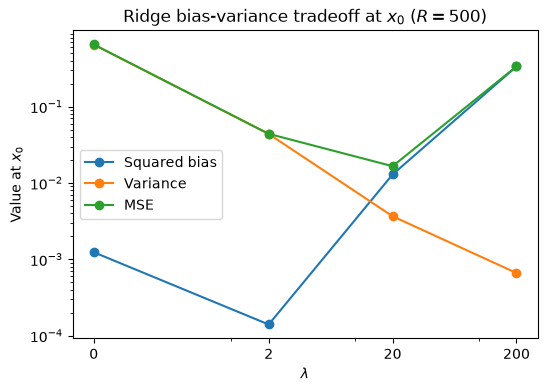

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(q6_table["lambda"], q6_table["bias_sq"], marker="o", label="Squared bias")
ax.plot(q6_table["lambda"], q6_table["variance"], marker="o", label="Variance")
ax.plot(q6_table["lambda"], q6_table["MSE"], marker="o", label="MSE")
ax.set_xscale("symlog", linthresh=1)   # handles lambda = 0
ax.set_yscale("log")                   # values span ~4 orders of magnitude
ax.set_xticks(lambdas)
ax.set_xticklabels([f"{lam:g}" for lam in lambdas])
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"Value at $x_0$")
ax.set_title(r"Ridge bias-variance tradeoff at $x_0$ ($R = 500$)")
ax.legend()
plt.show()

### Q6 interpretation
This is consistent with our observation in questio### Q6 interpretation

This is consistent with our observation in Question 2. As $\lambda$ increases, the variance decreases sharply, from about $0.649$ at $\lambda = 0$ to about $0.0007$ at $\lambda = 200$, while the squared bias increases, reaching about $0.335$ at $\lambda = 200$. The small dip in squared bias between $\lambda = 0$ and $\lambda = 2$ is simulation noise: at $\lambda = 0$ ridge is OLS, which is unbiased, and the estimated bias of $-0.035$ is within about one Monte Carlo standard error ($\sqrt{0.649/500} \approx 0.036$) of zero. The variance at $\lambda = 0$ is large because the first two columns of $X$ are strongly correlated, which makes OLS unstable; ridge stabilizes it by shrinking the coefficients. Among the four values tried, the MSE is smallest at $\lambda = 20$ ($0.0166$), which is the sweet spot between bias and variance here, although the true best $\lambda$ could lie anywhere between $2$ and $200$. 2. As lambda increases, our sqaured bias increases, while our variance decreases. There is a sweet spot for lambda = 20. 

## Q7: Hitters — freeze choices before testing
Salary and log_salary are outcomes, not predictors. row_id only identifies rows. Do not use test outcomes in exploratory analysis, tuning, or preprocessing.

In [22]:
data = pd.read_csv(DATA / "hitters_hw1.csv")
features = ["Years", "Hits", "AtBat", "HmRun", "Runs", "RBI", "Walks", "PutOuts"]
development = data.loc[data["split"] == "development"].copy()
test_rows = data.loc[data["split"] == "test"].copy()
X_dev = development[features]
y_dev = development["log_salary"]
fold_ids = development["fold"].to_numpy()
cv_splits = [(np.flatnonzero(fold_ids != k), np.flatnonzero(fold_ids == k)) for k in range(5)]
assert len(development) == 210 and len(test_rows) == 53
assert set(development.row_id).isdisjoint(test_rows.row_id)
assert all(len(va) == 42 for tr, va in cv_splits)

In [23]:
# Q7(a)(i): development/test counts and validation-fold counts
print("Development players:", len(development))
print("Test players:       ", len(test_rows))
print("Validation-fold counts (development only):")
print(development["fold"].value_counts().sort_index().to_string())

Development players: 210
Test players:        53
Validation-fold counts (development only):
fold
0    42
1    42
2    42
3    42
4    42


**(a)(i)** The supplied assignments give 210 development players and 53 test players (210 + 53 = 263). The development set is split into five validation folds of 42 players each, so every development player is in exactly one validation fold, and each CV fit trains on 168 players and validates on 42.

**(a)(ii)** No. The 53 test players are a random holdout from the same period as the development players, so the test MSE estimates performance for other players from that same period, not for a future season. Between seasons, salaries can rise overall, teams can start valuing different statistics, and rules or the league structure can change, so the relationship between the eight inputs and log salary can shift. Since the model and the random test set both reflect the same period's relationship, this split cannot detect such drift; evaluating future-season performance would require training on earlier seasons and testing on a later one.


### Q2b

In [24]:
def cv_mse(model, X, y, splits):
    """Mean of the per-fold validation MSEs; a fresh clone is fit on each training fold."""
    fold_mses = []
    for train_idx, val_idx in splits:
        m = clone(model)
        m.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = m.predict(X.iloc[val_idx])
        fold_mses.append(np.mean((y.iloc[val_idx].to_numpy() - pred) ** 2))
    return np.mean(fold_mses)

def cv_mse_baseline(y, splits):
    """Baseline: predict each validation fold with its training folds' mean log salary."""
    fold_mses = []
    for train_idx, val_idx in splits:
        pred = y.iloc[train_idx].mean()
        fold_mses.append(np.mean((y.iloc[val_idx].to_numpy() - pred) ** 2))
    return np.mean(fold_mses)

# Candidates in the listed order (ties are broken by this order)
candidates = []
for a in [0.1, 1, 10, 100, 1000]:
    candidates.append(("Ridge", f"alpha={a:g}",
                       make_pipeline(StandardScaler(), Ridge(alpha=a))))
for leaves in [3, 9, 20]:
    candidates.append(("Tree", f"max_leaves={leaves}",
                       DecisionTreeRegressor(max_leaf_nodes=leaves, min_samples_leaf=5,
                                             random_state=SEED)))
for mf in [1, 3, 8]:
    candidates.append(("RF/bagging", f"max_features={mf}",
                       RandomForestRegressor(n_estimators=200, max_features=mf,
                                             min_samples_leaf=5, bootstrap=True,
                                             max_depth=None, random_state=SEED)))
for eta, M in [(0.03, 100), (0.03, 300), (0.10, 100), (0.10, 300)]:
    candidates.append(("Boosting", f"eta={eta:g}, M={M}",
                       GradientBoostingRegressor(loss="squared_error", learning_rate=eta,
                                                 n_estimators=M, max_leaf_nodes=3,
                                                 min_samples_leaf=5, random_state=SEED)))

model_lookup = {(fam, setting): model for fam, setting, model in candidates}

cv_rows = [{"family": "Baseline", "setting": "training-fold mean",
            "CV_MSE": cv_mse_baseline(y_dev, cv_splits)}]
for fam, setting, model in candidates:
    cv_rows.append({"family": fam, "setting": setting,
                    "CV_MSE": cv_mse(model, X_dev, y_dev, cv_splits)})
cv_results = pd.DataFrame(cv_rows)
cv_results.round(4)

,family,setting,CV_MSE
0,Baseline,training-fold mean,0.7935
1,Ridge,alpha=0.1,0.4402
2,Ridge,alpha=1,0.4391
3,Ridge,alpha=10,0.4370
4,Ridge,alpha=100,0.4596
5,Ridge,alpha=1000,0.6262
6,Tree,max_leaves=3,0.3716
7,Tree,max_leaves=9,0.4103
8,Tree,max_leaves=20,0.4033
9,RF/bagging,max_features=1,0.4241


In [26]:
# Best setting per family (idxmin returns the first listed candidate on ties)
best_idx = cv_results.groupby("family", sort=False)["CV_MSE"].idxmin()
selected = cv_results.loc[best_idx].reset_index(drop=True)
chosen = selected.loc[selected["CV_MSE"].idxmin()]

print(selected.round(4).to_string())
print(f"\nCV-selected predictor (frozen before testing): "
      f"{chosen['family']} ({chosen['setting']}), CV MSE = {chosen['CV_MSE']:.4f}")

       family             setting  CV_MSE
0    Baseline  training-fold mean  0.7935
1       Ridge            alpha=10  0.4370
2        Tree        max_leaves=3  0.3716
3  RF/bagging      max_features=8  0.2971
4    Boosting      eta=0.1, M=100  0.3208

CV-selected predictor (frozen before testing): RF/bagging (max_features=8), CV MSE = 0.2971


**(b)(ii)** Using the common five folds, the CV-selected setting in each family is:

| Family | Selected setting | CV MSE |
|---|---|---|
| Baseline | training-fold mean | 0.7935 |
| Ridge | $\alpha = 10$ | 0.4370 |
| Single tree | 3 leaves | 0.3716 |
| RF / bagging | `max_features` = 8 (bagging) | 0.2971 |
| Boosting | $\eta = 0.10$, $M = 100$ | 0.3208 |

The overall CV-selected predictor is bagging (random forest with `max_features` = 8), which has the lowest CV MSE of all candidates, including the baseline. Every model improves substantially on the baseline, and the tree-based ensembles all outperform ridge, suggesting that the relationship between the performance statistics and log salary is not purely linear. This choice is frozen before any test scores are

In [28]:
X_test = test_rows[features]
y_test = test_rows["log_salary"].to_numpy()

test_preds = {}
test_mses = []
for _, row in selected.iterrows():
    if row["family"] == "Baseline":
        pred = np.full(len(y_test), y_dev.mean())   # full development mean
    else:
        final_model = clone(model_lookup[(row["family"], row["setting"])])
        final_model.fit(X_dev, y_dev)               # refit on all development rows
        pred = final_model.predict(X_test)
    test_preds[row["family"]] = pred
    test_mses.append(np.mean((y_test - pred) ** 2))

final_table = selected.assign(Test_MSE=test_mses)
final_table.round(4)

,family,setting,CV_MSE,Test_MSE
0,Baseline,training-fold mean,0.7935,0.7853
1,Ridge,alpha=10,0.4370,0.3670
2,Tree,max_leaves=3,0.3716,0.4098
3,RF/bagging,max_features=8,0.2971,0.2845
4,Boosting,"eta=0.1, M=100",0.3208,0.2531


**(c)** Each selected setting was refit on all 210 development players and evaluated once on the 53 test players (the baseline uses the full development mean). The table above adds the test MSEs to the CV MSEs.

Two pairs swap places on the test set: boosting (0.2531) overtakes the preselected bagging model (0.2845), and ridge (0.3670) overtakes the single tree (0.4098). The chosen predictor remains bagging, because it was frozen before testing:

- The test set is small (53 players), so each test MSE is a noisy estimate; a different sample of 53 players would give different values.
- The CV gap between bagging and boosting was small (about 0.024), and so is the test gap, so neither ordering is strong evidence that one method is universally better.
- Switching to boosting now would use the test set for model selection, making its error optimistic and no longer an independent assessment.
- Bagging still clearly outperforms the baseline, ridge, and the single tree on the test set.

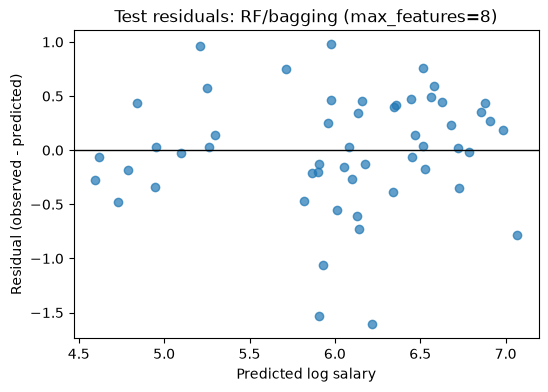

In [29]:
pred_chosen = test_preds[chosen["family"]]
residuals = y_test - pred_chosen          # observed minus predicted

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(pred_chosen, residuals, alpha=0.7)
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Predicted log salary")
ax.set_ylabel("Residual (observed - predicted)")
ax.set_title(f"Test residuals: {chosen['family']} ({chosen['setting']})")
plt.show()

**(d)(ii)** The test residuals are centered around zero across the range of predictions, with no clear curved pattern, so the bagging model does not appear to systematically under- or overpredict at particular salary levels. The most notable feature is a few large negative residuals (about $-1.1$ to $-1.6$) for players predicted near 6.0, meaning the model substantially overpredicted their salaries. This suggests that salary also depends on factors not captured by the eight performance inputs, such as contract status. With only 53 test players, any apparent change in spread should be interpreted cautiously.

## Acknowledgments

Claude was used for conceptual explanations, and to transcribe my handwritten derivations into LaTeX.